In [9]:
import os
import json
import requests
from typing import Annotated, List, TypedDict, Optional
import base64
from openai import OpenAI
from dotenv import load_dotenv
from langchain_core.messages import BaseMessage, HumanMessage, ToolMessage
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from qdrant_client import QdrantClient
from sentence_transformers import SentenceTransformer, CrossEncoder
from IPython.display import Image, display
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder

In [8]:
# Install required package for Google Generative AI
%pip install langchain-google-genai

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 36.0 MB/s  0:00:00

   ---------------------------------------- 0/6 [filetype]
   ------ --------------------------------- 1/6 [proto-plus]
   ------ --------------------------------- 1/6 [proto-plus]
   ------ --------------------------------- 1/6 [proto-plus]
   -------------------- ------------------- 3/6 [google-api-core]
   -------------------- ------------------- 3/6 [google-api-core]
   -------------------- ------------------- 3/6 [google-api-core]
   -------------------- ------------------- 3/6 [google-api-core]
   -------------------- ------------------- 3/6 [google-api-core]
   -------------------- ------------------- 3/6 [google-api-core]
   -------------------------- ------------- 4/6 [google-ai-generativelanguage]
   -------------------------- ------------- 4/6 [google-ai-generat

In [10]:
# --- 1. Load Environment Variables ---
# Make sure you have a .env file with your GROQ_API_KEY
load_dotenv()

# --- 2. Define the State for our Graph ---
# This is simplified from your original agent.
# The `messages` list is the core of the state, tracking the conversation.
# add_messages is a helper that appends new messages instead of overwriting the list.
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]
    image_path: Optional[str]

# --- 3. Initialize Models and Tools ---
# Initialize the embedding and reranking models
embedding_model = SentenceTransformer('all-MiniLM-L6-v2')
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")

# Initialize the Qdrant client
# Ensure your Qdrant instance is running
try:
    client = QdrantClient(host="localhost", port=6333, timeout=10.0)
    client.get_collections() # Test connection
    print("Successfully connected to Qdrant.")
except Exception as e:
    print(f"Failed to connect to Qdrant: {e}")
    client = None # Set client to None if connection fails


Successfully connected to Qdrant.


C:\Users\jihed\AppData\Local\Temp\ipykernel_12388\155414294.py:21: UserWarning: Qdrant client version 1.15.1 is incompatible with server version 1.13.5. Major versions should match and minor version difference must not exceed 1. Set check_compatibility=False to skip version check.
  client = QdrantClient(host="localhost", port=6333, timeout=10.0)


In [11]:
# --- 4. Define Agent Tools ---
# We convert your node functions into tools using the `@tool` decorator.
# The LLM will use the function signature and docstring to decide when to call them.


@tool
def vision_tool(image_path: str) -> str:
    """
    Analyse une image médicale à partir d'un chemin de fichier et retourne une description détaillée.
    Utilise cet outil en PREMIER si l'utilisateur fournit une image.

    Args:
        image_path (str): Le chemin du fichier local vers l'image à analyser.
    """
    print(f"--- Exécution de Vision Tool pour l'image : {image_path} ---")
    try:
        with open(image_path, "rb") as image_file:
            image_b64 = base64.b64encode(image_file.read()).decode("utf-8")
    except Exception as e:
        return f"Erreur lors de la lecture du fichier image : {e}"
    image_url = f"data:image/jpeg;base64,{image_b64}"
    headers = {
        "Authorization": f"Bearer {os.getenv('OPENROUTER_API_KEY')}", "Content-Type": "application/json"
    }
    payload = {
        "model": "qwen/qwen-vl-plus",
        "messages": [{"role": "user", "content": [
            {"type": "image_url", "image_url": {"url": image_url}},
            {"type": "text", "text": "Décris cette image médicale en détail."}
        ]}]
    }
    try:
        response = requests.post("https://openrouter.ai/api/v1/chat/completions", json=payload, headers=headers)
        response.raise_for_status()
        description = response.json()["choices"][0]["message"]["content"]
        print("--- L'outil de vision a réussi ---")
        return description
    except Exception as e:
        print(f"--- L'outil de vision a échoué : {e} ---")
        return f"Erreur lors de l'appel de l'API Vision : {e}"
    
@tool
def decomposer_tool(complex_question: str) -> List[str]:
    """
    Décompose une question complexe de l'utilisateur en une liste de sous-questions plus simples.
    À utiliser pour les questions contenant des mots comme "et", "puis", "comparer", "après", etc.
    
    Args:
        complex_question (str): La question complexe de l'utilisateur.
    """
    print(f"--- Exécution de Decomposer Tool pour la question : {complex_question} ---")
    try:
        client = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=os.getenv('OPENROUTER_API_KEY'))
        prompt = f"""Décompose la question de l'utilisateur en une liste de sous-questions simples. Retourne une liste JSON de chaînes de caractères dans une clé "sub_questions". Question : {complex_question}"""
        completion = client.chat.completions.create(
            model="mistralai/mistral-7b-instruct",
            messages=[{"role": "user", "content": prompt}],
            response_format={"type": "json_object"}
        )
        result = completion.choices[0].message.content
        sub_questions = json.loads(result).get("sub_questions", [complex_question])
        print(f"--- Décomposé en : {sub_questions} ---")
        return sub_questions
    except Exception as e:
        print(f"--- L'outil de décomposition a échoué : {e} ---")
        return [complex_question]

@tool
def retriever_tool(query: str) -> List[dict]:
    """
    Récupère des extraits pertinents ET LEURS MÉTADONNÉES depuis la base de données Qdrant.
    Chaque extrait retourné est un dictionnaire avec une clé 'content' et une clé 'metadata'.
    Args:
        query (str): La requête de recherche pour trouver des documents médicaux pertinents.
    """
    if not client: return [{"error": "Client Qdrant non disponible."}]
    print(f"--- Exécution de Retriever Tool avec la requête : {query} ---")
    
    results = client.search(
        collection_name="surgical_collection_multimodal", 
        query_vector=embedding_model.encode(query).tolist(), 
        limit=5, 
        with_payload=True
    )
    
    # NOUVELLE LOGIQUE : Extraire le contenu ET les métadonnées
    chunks = [
        {
            "content": res.payload.pop("content", ""), # Extrait et supprime le contenu du payload
            "metadata": res.payload # Le reste du payload est considéré comme métadonnées
        } 
        for res in results if res.payload and "content" in res.payload
    ]
    print(f"Récupéré {len(chunks)} extraits avec leurs métadonnées.")
    return chunks

@tool
def reranker_tool(query: str, chunks: List[dict]) -> List[dict]:
    """
    Reclasse une liste d'extraits de documents (avec leurs métadonnées) en fonction de leur pertinence.
    Args:
        query (str): La requête de recherche originale.
        chunks (List[dict]): Une liste d'extraits, chaque extrait étant un dictionnaire avec 'content' et 'metadata'.
    Returns:
        List[dict]: Les 5 extraits les plus pertinents, avec leurs métadonnées intactes.
    """
    print(f"--- Exécution de Reranker Tool pour la requête : {query} ---")
    if not chunks: return []
    
    # Le contenu est utilisé pour le score, mais l'objet entier (avec métadonnées) est conservé
    pairs = [(query, chunk['content']) for chunk in chunks]
    scores = reranker.predict(pairs)
    
    reranked = sorted(zip(chunks, scores), key=lambda x: x[1], reverse=True)
    
    top_chunks = [chunk for chunk, score in reranked[:5]]
    print(f"Extraits reclassés, retournant le top {len(top_chunks)}.")
    return top_chunks

In [12]:
system_prompt = """You are **Medical Assistant AI**, an intelligent and multimodal research agent.

---
### **Persona**
- **Professional and Factual:** Your answers are based solely on retrieved data.
- **Cautious:** You never speculate and always state your limitations (no diagnoses).
- **Methodical:** You rigorously follow the process below.

---
### 🎯 **Your Mission**
To answer the user's medical questions by using a suite of tools to build a complete, factual, and **sourced** answer.

---
### 🚫 **Strict Boundaries (Non-Negotiable)**
1.  **Exclusive Domain:** You **never** answer non-medical questions.
2.  **No Diagnosis or Advice:** You **never** provide a diagnosis or personalized medical advice. You **must** redirect the user to a healthcare professional if they ask for it.

---
### 🧠 **Reasoning and Action Process**

**1. Analysis and Planning:**
   - **Decomposition:** If the question is complex, use `decomposer_tool`.
   - **Image Detection:** If an image is provided, your first action is to call `vision_tool`.

**2. Information Gathering:**
   - **Create Query:** Merge the user's question and the image description (if available) to create the best possible search query.
   - **Retrieve Data:** Call `retriever_tool`. This is a **mandatory** step.
   - **Refine Data (Optional):** Use `reranker_tool` if the results are too broad.

**3. Synthesis and Final Answer:**
   - Once you have gathered all necessary information, **stop calling tools**.
   - **Formulate the Answer:** Write a clear, synthetic answer based **only** on the `content` of the chunks provided by the tools.
   - **Do Not Describe Your Process:** Provide the final answer directly.
   - **Handle Empty Results:** If a tool finds nothing (`[]`), inform the user.


---
### 🔧 **Tool Usage Rules**
- `vision_tool(image_path: str)`
- `decomposer_tool(complex_question: str)`
- `retriever_tool(query: str)`: Returns content and metadata for sourcing.
- `reranker_tool(query: str, chunks: List[dict])`: Reranks chunks while preserving metadata.

---
### 📦 **Tool Call Format**
- Always formulate arguments in a **valid, compact JSON format**.
"""
    # This goes in section 5, where you set up the agent
prompt = ChatPromptTemplate.from_messages(
        [
            ("system", system_prompt),
            MessagesPlaceholder(variable_name="messages"),
        ]
)

In [13]:
tools = [
    vision_tool,
    decomposer_tool,
    retriever_tool,
    reranker_tool
]
# --- 5. Set up the Agent (LLM with Tools) ---
# We use ChatGoogleGenerativeAI with the Gemini 2.5 Pro model and bind our tools to it.
# The LLM will now be able to decide when to call these tools.
llm = ChatGoogleGenerativeAI(
    model="gemini-2.0-flash-exp", 
    temperature=0,
    google_api_key=os.getenv('GOOGLE_API_KEY')
)
llm_with_tools = llm.bind_tools(tools)
agent_chain = prompt | llm_with_tools # This combines the prompt with the LLM and tools.

# --- 6. Define the Graph Nodes ---
# This is the primary node of our graph. It invokes the LLM with the current state.
def agent_node(state: AgentState):
    """Invoque le LLM avec tout le contexte pour décider de la prochaine action."""
    print("--- Appel du Nœud Agent ---")
    
    current_messages = state["messages"]
    
    # Si un chemin d'image est présent dans l'état, ajoute un message système pour en informer l'IA
    if state.get("image_path"):
        # On vérifie qu'on ne l'a pas déjà ajouté pour éviter les doublons dans la boucle
        if not any("[Image provided at path:" in msg.content for msg in current_messages):
             image_message = HumanMessage(content=f"[Image provided at path: {state['image_path']}]")
             current_messages.append(image_message)
        
    response = agent_chain.invoke({"messages": current_messages})
    return {"messages": [response]}

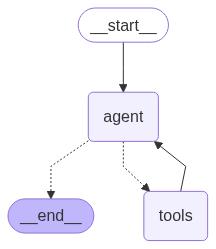

In [14]:

# The ToolNode is a pre-built node from LangGraph that executes tool calls.
tool_node = ToolNode(tools)

# --- 7. Build the Graph (ReAct Architecture) ---
# This defines the flow of our agent.
builder = StateGraph(AgentState)

# Add the agent node and the tool node
builder.add_node("agent", agent_node)
builder.add_node("tools", tool_node)

# Set the entry point
builder.set_entry_point("agent")

# Add the conditional edge. This is the core of the ReAct loop.
# Based on the output of the 'agent' node, it decides whether to
# call the 'tools' node or end the process.
builder.add_conditional_edges(
    "agent",
    tools_condition, # A pre-built function that checks for tool calls
)

# Add an edge from the 'tools' node back to the 'agent' node.
# This allows the agent to reflect on the tool output and decide the next step.
builder.add_edge("tools", "agent")

# --- 8. Add Memory (Checkpointer) ---
# This makes the agent stateful, allowing it to remember conversation history.
memory = MemorySaver()
graph = builder.compile(checkpointer=memory)

# --- 9. Visualize and Run the Agent ---
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print("Could not display graph. Please install pydot and graphviz.")



In [15]:
config = {"configurable": {"thread_id": "medical-assistant-thread-multimodal-1"}}
while True:
    user_input = input("Utilisateur : ")
    if user_input.lower() in ["quit", "exit", "q"]:
        break
    
    image_path = input("Chemin de l'image (optionnel, appuyez sur Entrée pour ignorer) : ")
    
    # Préparer l'état initial pour l'invocation
    initial_state = {
        "messages": [HumanMessage(content=user_input)],
        "image_path": image_path if image_path else None
    }
    
    events = graph.stream(initial_state, config=config, stream_mode="values")
    for event in events:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

what is diabete
--- Appel du Nœud Agent ---
================================== Ai Message ==================================
Tool Calls:
  retriever_tool (b2f1a06b-a633-401e-8347-7eb83da6ccae)
 Call ID: b2f1a06b-a633-401e-8347-7eb83da6ccae
  Args:
    query: what is diabetes
--- Exécution de Retriever Tool avec la requête : what is diabetes ---
Récupéré 5 extraits avec leurs métadonnées.
================================= Tool Message =================================
Name: retriever_tool

[{"content": "Presence of diabetes mellitus ", "metadata": {"title": "C.", "chapter": "Abdominal Wall, Including Hernia", "section": "SUGGESTED READINGS", "subsection": null, "is_figure": false, "is_table": false}}, {"content": "Diabetic ketoacidosis (DKA) can develop in patients with either type I or type II diabetes. DKA is deceptively easy to overlook because it can mimic postoperative ileus. It may present as nausea,

C:\Users\jihed\AppData\Local\Temp\ipykernel_12388\683903585.py:79: DeprecationWarning: `search` method is deprecated and will be removed in the future. Use `query_points` instead.
  results = client.search(


================================== Ai Message ==================================

Diabetes mellitus is a condition characterized by the presence of hyperglycemia. While diabetes may be the cause in some patients, hyperglycemia in critically ill patients is commonly caused by increased sympathetic and adrenal activity and activation of the cytokine cascade.
================================ Human Message =================================


--- Appel du Nœud Agent ---
================================ Human Message =================================


--- Appel du Nœud Agent ---


c:\Users\jihed\OneDrive\Bureau\Thesis\MIAS_RAG\final_version\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:1805: UserWarning: HumanMessage with empty content was removed to prevent API error
  warnings.warn(


================================== Ai Message ==================================

 The management of diabetic patients includes achieving euglycemia.


KeyboardInterrupt: Interrupted by user